In [32]:
import subprocess as sp
import pandas as pd
import numpy as np
import os
from io import StringIO
from tqdm import tqdm
import seaborn as sns
import matplotlib.pyplot as plt
from itertools import product

In [52]:
dirname = os.environ['GSET'] + '/edwards_anderson/'
filelist = [os.path.join(dirname, f'edwards_anderson_bimodal_l_6_{i}.gset') for i in range(10)]
option_str = '-p {} -r {} --seed {} --pts {} --beta0 {} --beta1 {}'
options = list(product(filelist, [10,20,40], range(5), [np.exp(i) for i in range(10)], [0.1], [1.6]))
print(len(options))

1500


In [56]:
dflist = []
for opt_comb in tqdm(options):
    arglist = option_str.format(*opt_comb).strip().split()
    output = sp.run(['./pt_icm'] + arglist, stdout=sp.PIPE)
    output_csv = '\n'.join(output.stdout.decode().splitlines()[-2:])
    dflist.append(pd.read_csv(StringIO(output_csv)))
    

100%|██████████| 1500/1500 [04:25<00:00,  5.65it/s]


In [57]:
df = pd.concat(dflist)
ref_df = pd.read_csv(os.environ['GSET'] + '/edwards_anderson/summary.txt')
ref_df = ref_df.rename(columns={'Graph': 'graph', 'Max': 'sa_cut'})
df = df.merge(ref_df, on='graph')
df['GS'] = (df['cut'] == df['sa_cut'])

       ln(t)  Nt  energy     cut        flips     swaps     pts  nodes  seed   
0   0.000000  10 -226.24  115.12      2134.62      2.00     1.0  216.0   2.0  \
1   0.000000  20 -229.20  116.60      4255.46      2.00     1.0  216.0   2.0   
2   0.000000  40 -231.04  117.52      8512.70      2.00     1.0  216.0   2.0   
3   0.693147  10 -304.08  154.04      3401.08      3.32     2.0  216.0   2.0   
4   0.693147  20 -306.16  155.08      6785.52      3.38     2.0  216.0   2.0   
5   0.693147  40 -307.52  155.76     13568.98      3.36     2.0  216.0   2.0   
6   1.945910  10 -362.80  183.40      6787.58      9.34     7.0  216.0   2.0   
7   1.945910  20 -364.32  184.16     13512.10     10.26     7.0  216.0   2.0   
8   1.945910  40 -365.84  184.92     26933.96     10.80     7.0  216.0   2.0   
9   2.995732  10 -373.36  188.68     13461.34     23.58    20.0  216.0   2.0   
10  2.995732  20 -375.20  189.60     26652.86     30.82    20.0  216.0   2.0   
11  2.995732  40 -375.20  189.60     530

<Axes: xlabel='ln(t)', ylabel='GS'>

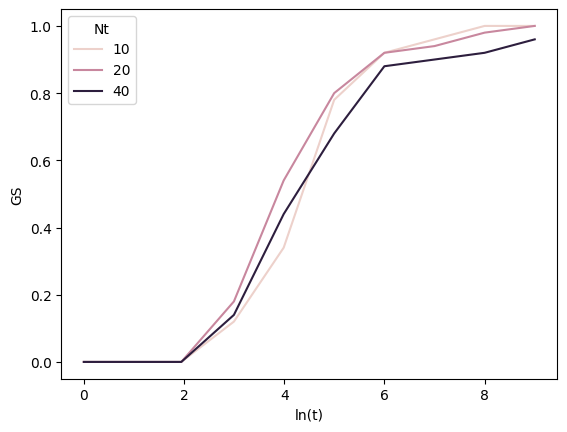

In [58]:

df['ln(t)'] = np.log(df['pts'])
mean_df = df.groupby(['ln(t)', 'Nt']).mean(numeric_only=True).reset_index()
print(mean_df)
sns.lineplot(data=mean_df, x='ln(t)', y='GS', hue='Nt')

In [59]:
df.to_csv('pt_icm_ea_l6.csv', index=False)